# Part 4 — Stage A → B → C: 입력 형식 결정과 규모 확대

**목적** Stage 0으로 파이프라인이 정상임을 확인한 뒤, (1) 작은 규모(Stage A, 2,000건)에서 입력 형식을 정하고
(2) 그 설정으로 규모를 20,000건(Stage B) → 전체 278,292건(Stage C)으로 늘려 점수가 실제로 오르는지 확인한다.

**원칙** 한 번에 한 변수만 바꾼다. 차이는 paired bootstrap 95% 구간으로 판단하고, 구간이 0을 포함하면 "차이를 확인하지 못했다"고 쓴다.
모든 점수는 dev 1,500건, 디코딩 `beam4/nrng0/lp1.0/max64`, ROUGE-L은 space(공백)·morph(형태소) 두 기준이다.
이 노트북의 점수는 학습 직후 평가(`src/train.py`) 값이다.

**실행한 것**
```
python scripts/train.py --config configs/stage_a.yaml --name a_base_speaker_drop
python scripts/train.py --config configs/stage_a.yaml --name a_ser_plain   --set preprocess.serialization=plain
python scripts/train.py --config configs/stage_a.yaml --name a_ser_turn    --set preprocess.serialization=turn
python scripts/train.py --config configs/stage_a.yaml --name a_systag_type --set preprocess.system_tag=type
python scripts/train.py --config configs/stage_b.yaml --name b_speaker_drop
python scripts/train.py --config configs/stage_c.yaml --name c_speaker_drop
python scripts/compare_runs.py --base <기준 run> --runs <비교 run...> --name <이름>
```

In [1]:
import sys, json, yaml
from pathlib import Path
sys.path.insert(0, "..")
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 120)
RUNS, EVAL = Path("../artifacts/runs"), Path("../artifacts/eval")
def last(pattern, base=RUNS):
    return sorted(base.glob(pattern))[-1]
def metrics(d):
    return json.loads((d / "metrics.json").read_text(encoding="utf-8"))

## 1. 각 run의 설정과 결과

In [2]:
names = ["a_base_speaker_drop", "a_ser_plain", "a_ser_turn", "a_systag_type", "b_speaker_drop", "c_speaker_drop"]
rows = []
for n in names:
    d = last(f"*_{n}"); m = metrics(d); c = yaml.safe_load((d / "config.yaml").read_text(encoding="utf-8"))
    rows.append({"run": n, "train 건수": m["n_train"], "직렬화": c["preprocess"]["serialization"],
                 "system_tag": c["preprocess"]["system_tag"], "epoch": c["train"]["num_train_epochs"],
                 "스텝": m["global_step"], "ROUGE-L space": m["rouge"]["space"]["rougeL"],
                 "ROUGE-L morph": m["rouge"]["morph"]["rougeL"], "반복4gram(예측%)": m["repeat_ngram_pct"]["pred"]["n4"],
                 "학습(분)": round(m["train_sec"] / 60, 1), "peak VRAM(GB)": m["peak_vram_gb"]})
pd.DataFrame(rows).set_index("run")

,train 건수,직렬화,system_tag,epoch,스텝,ROUGE-L space,ROUGE-L morph,반복4gram(예측%),학습(분),peak VRAM(GB)
run,,,,,,,,,,
a_base_speaker_drop,2000,speaker,drop,3,375,22.632,41.327,8.20,12.5,7.15
a_ser_plain,2000,plain,drop,3,375,22.834,41.343,7.87,11.7,6.97
a_ser_turn,2000,turn,drop,3,375,22.387,41.150,8.73,12.0,7.11
a_systag_type,2000,speaker,type,3,375,22.741,41.457,10.73,12.6,7.15
b_speaker_drop,20000,speaker,drop,2,2500,25.157,43.538,7.67,38.3,7.19
c_speaker_drop,278292,speaker,drop,2,34788,27.325,45.188,7.00,371.2,7.18


## 2. Stage A — 입력 형식 비교 (2,000건)

- ② 직렬화: `speaker`(화자 표시, 기준) / `plain`(발화만) / `turn`(같은 턴 발화를 한 줄로)
- ③ 시스템 태그: `drop`(`#@시스템#사진#` 삭제, 기준) / `type`(`[사진]`으로 치환)

In [3]:
def compare_table(name):
    d = last(f"*_{name}", EVAL); r = json.loads((d / "compare.json").read_text(encoding="utf-8"))
    out = [{"run": r["base"] + " (기준)", "space": r["base_rougeL"]["space"], "morph": r["base_rougeL"]["morph"]}]
    for x in r["compare"]:
        out.append({"run": x["run"], "space": x["rougeL"]["space"], "morph": x["rougeL"]["morph"],
                    "space 차이 [95% CI]": f'{x["space"]["diff"]:+.3f} [{x["space"]["ci95"][0]:+.3f}, {x["space"]["ci95"][1]:+.3f}]',
                    "morph 차이 [95% CI]": f'{x["morph"]["diff"]:+.3f} [{x["morph"]["ci95"][0]:+.3f}, {x["morph"]["ci95"][1]:+.3f}]',
                    "판정": "차이 확인" if x["space"]["excludes_zero"] and x["morph"]["excludes_zero"] else "차이를 확인하지 못함"})
    return pd.DataFrame(out).set_index("run")
display(compare_table("stage_a_serialization"))
display(compare_table("stage_a_system_tag"))

,space,morph,space 차이 [95% CI],morph 차이 [95% CI],판정
run,,,,,
20260919_152236_a_base_speaker_drop (기준),22.632,41.327,NaN,NaN,NaN
20260919_154047_a_ser_plain,22.834,41.343,"+0.201 [-0.385, +0.776]","+0.016 [-0.528, +0.565]",차이를 확인하지 못함
20260919_155516_a_ser_turn,22.387,41.150,"-0.245 [-0.873, +0.368]","-0.177 [-0.714, +0.369]",차이를 확인하지 못함


,space,morph,space 차이 [95% CI],morph 차이 [95% CI],판정
run,,,,,
20260919_152236_a_base_speaker_drop (기준),22.632,41.327,NaN,NaN,NaN
20260919_161329_a_systag_type,22.741,41.457,"+0.109 [-0.404, +0.640]","+0.129 [-0.367, +0.617]",차이를 확인하지 못함


**결정: `speaker` / `drop`** (사용자 확인)

- 모든 구간이 0을 포함한다. 바꿀 근거가 없으므로 기준을 유지한다
- `speaker`는 "누가"를 알 수 있게 하라는 가이드라인 규칙 2에 필요한 화자 정보를 입력에 남긴다
- `type`은 반복 4-gram 비율이 기준보다 높았다(10.7% vs 8.2%)
- 한계: 시드 1개, 2,000건. ±0.2 수준 차이는 시드 노이즈와 구분할 수 없다

## 3. Stage B, C — 규모 확대

In [4]:
display(compare_table("stage_b_vs_a"))
display(compare_table("stage_c_vs_b"))

,space,morph,space 차이 [95% CI],morph 차이 [95% CI],판정
run,,,,,
20260919_152236_a_base_speaker_drop (기준),22.632,41.327,NaN,NaN,NaN
20260919_163231_b_speaker_drop,25.157,43.538,"+2.525 [+1.796, +3.225]","+2.211 [+1.528, +2.840]",차이 확인


,space,morph,space 차이 [95% CI],morph 차이 [95% CI],판정
run,,,,,
20260919_163231_b_speaker_drop (기준),25.157,43.538,NaN,NaN,NaN
20260919_172416_c_speaker_drop,27.325,45.188,"+2.169 [+1.362, +2.873]","+1.650 [+0.936, +2.271]",차이 확인


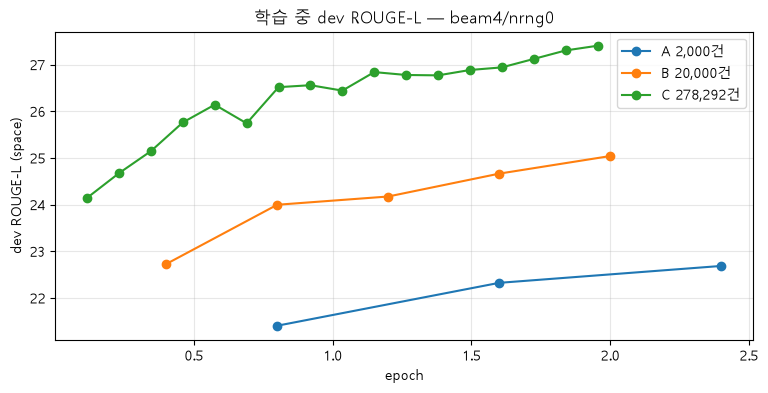

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for n, label, ep in [("a_base_speaker_drop", "A 2,000건", 3), ("b_speaker_drop", "B 20,000건", 2), ("c_speaker_drop", "C 278,292건", 2)]:
    m = metrics(last(f"*_{n}")); h = m["eval_history_space_rougeL"]; total = m["global_step"]
    ax.plot([x["step"] / total * ep for x in h], [x["rougeL"] for x in h], marker="o", label=label)
ax.set_xlabel("epoch"); ax.set_ylabel("dev ROUGE-L (space)"); ax.set_title("학습 중 dev ROUGE-L — beam4/nrng0")
ax.grid(alpha=.3); ax.legend(); plt.show()

**관찰**

- 규모를 키울 때마다 차이를 확인했다: B − A +2.5, C − B +2.2 (space 기준, 구간이 0을 넘는다)
- Stage A→B는 데이터(×10)와 epoch(3→2)가 함께 바뀌었다. 데이터 규모만의 효과로 해석하지 않는다
- Stage C는 마지막 평가(34,000 스텝)가 best였다. 2 epoch 끝까지 조금씩 올랐으므로 수렴했다고 보지 않는다
- 중간에 한 번 떨어졌다가(12k 25.74) 다시 오르는 등, dev 1,500건 ROUGE는 평가마다 ±0.4 정도 흔들린다

**운영 메모** Stage A 첫 시도가 시스템 다운(bugcheck 0x101)으로 끊겼다. 평가 batch를 32→8로 줄인 뒤 재실행했고,
Stage C 전에는 `--resume`(체크포인트 이어하기)을 추가해, 강제 종료 후 이어한 run이 끊지 않은 run과 소수점까지 같음을 확인했다.